# 🔎 RAG, langchain 실습

## 관련 라이브러리 설치

In [1]:
# langchain 관련
!pip -q install -U langchain langchain-community langgraph langchain-text-splitters
# chromadb: 벡터를 저장하는 로컬 DB)
!pip -q install -U chromadb
# tavily 관련: 웹 검색 API
!pip -q install -U tavily-python beautifulsoup4 lxml html5lib
# 시각화 관련: langchain으로 노드 기반 파이프라인 구성
# !pip -q install -U pydot graphviz  # 선택사항

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatibl

In [2]:
%pip install -U --no-cache-dir "google-genai==2.33.0" "langchain-google-genai==4.4.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.1 MB/s  0:00:00
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [langchain-google-genai]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 

## Api키 값 입력

google gemini, tavily api 키 값입니다!      

**발급한 api 키는 개인 계정 키 값이기 때문에 외부 유출 ❌ 절대 깃허브에도 올리지 말아주세요!!!!!**

🔗 라이브러리 링크

* Google AI Studio : https://aistudio.google.com
  * gemini 모델들을 api로 사용하기 위한 곳
* tavily : https://www.tavily.com/
  * llm이나 agent을 위한 웹 검색 엔진 (ai 툴이랑 연동이 잘 돼요)
**필수: Google AI Studio와 Tavily 사이트에서 각자 API 키를 발급해 아래 셀의 입력창에 넣습니다.**

In [3]:
import os
from getpass import getpass

# gemini api키 (원한다면 본인 계정으로 넣어도 돼요)
os.environ["GOOGLE_API_KEY"] = getpass("Gemini API 키 입력: ")

# tavily api키 (원한다면 본인 계정으로 넣어도 돼요)
os.environ["TAVILY_API_KEY"] = getpass("Tavily API 키 입력: ")

Gemini API 키 입력: ··········
Tavily API 키 입력: ··········


# RAG 적용 전 결과 확인해보기

In [4]:
from google import genai
import os

# gemini 클라이언트 생성
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

# 📌사용자 질문 -> 원하시는 질문으로 바꿔도 됩니다!!📌
question = "2026년 WBC 우승 국가를 알려주세요."

# 모델 직접 호출
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=question,
    config={
        # temperature: 모델의 창의성, 다양성을 조절하는 값.
        # 사실 기반 답변을 받으려면 0으로 설정 (1에 가까울수록 창의적 답변)
        "temperature": 0
    }
)

print("=" * 50)
print("💡 1. RAG 적용 전 결과")
print(f"질문: {question}")
print("-" * 50)
print(response.text)
print("=" * 50)

💡 1. RAG 적용 전 결과
질문: 2026년 WBC 우승 국가를 알려주세요.
--------------------------------------------------
2026년 WBC(월드 베이스볼 클래식)는 아직 개최되지 않았기 때문에 우승 국가는 아직 정해지지 않았습니다. 

2026년 WBC는 **2026년 3월**에 개최될 예정입니다. (본선 경기는 미국의 휴스턴과 마이애미, 일본 도쿄, 푸에르토리코 산후안 등에서 열립니다.) 

대회가 열리고 결승전이 끝나야 우승 국가를 알 수 있습니다.


RAG를 적용하지 않은 모델의 답변은 최신 정보를 정확히 반영하지 못할 수 있습니다.

그래서 이제 RAG를 사용해서 저희가 원하는 정보를 제대로 답변하는 모델을 만들어 볼게요!

# 📝 RAG 적용

저희는 RAG를 구축할 때, tavily라는 웹 검색 엔진을 연동해서 사용자 질문을 웹에서 검색하여 정보를 얻으려고 합니다!

간단한 구조이긴 하지만, 공부를 위해서 langchain, langgraph까지 활용해서 답변 과정을 구성하고 모니터링까지 해보겠습니다

## 라이브러리 import

In [5]:
from typing import TypedDict, List, Any
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

# LLM / Embeddings
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings

# Search / Load / Vectorstore
from tavily import TavilyClient
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import Chroma

# Prompt & Parser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# LangGraph
from langgraph.graph import StateGraph, END

/tmp/ipykernel_960/938159975.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


## 🟨 노드 구성 🟨

**RAGState**는 그래프 구조에 대한 스키마입니다!!<br>(말이 어렵죠? 그냥 파이프 라인에 대한 개념 정의 코드라고 생각하면 됩니다...)

<U>여러분들이 노션에서 데이터베이스 블럭을 만드는 거라고 생각하면 돼요!</U>

### 🙋🏻 노드 설명

실습에서는 6개 노드로 구성했습니다 각 노드의 역할을 알려드릴게요

* `node_search()` : **검색**
  * tavily api로 <U>url 검색</U>
* `node_load()` : **웹 문서 로드**
  * 각 url에 대해 크롤링 -> <U>'document' 형식으로 변환</U>
* `node_split()` : **청크 분할**
  * <U>'document'를 chunk 단위로 쪼개기</U>, Overlap을 적용해서 각 청크마다 겹치게 설정
* `node_index()` : **벡터 인덱스 생성**
  * 청크를 <U>임베딩 처리해서 벡터db에 저장</U> (벡터db는 chroma, 임베딩 모델은 Gemini 임베딩 모델을 사용합니다!)
* `node_retrieve()` : **유사도 검색**
  * 벡터db에서 <U>유사도를 기반으로 사용자의 질문과 유사한 정보 검색</U>, 가장 유사한 청크 4개 return
* `node_generate()` : **답변 생성**
  * return 받은 청크들로 <U>context 생성</U>, 최종적으로 언어모델에 적용하기


In [6]:
import time
from langchain_community.vectorstores import Chroma

In [7]:
# --------- 그래프 상태 ---------
class RAGState(TypedDict):
    question: str
    urls: List[str]
    docs: List[Document]
    chunks: List[Document]
    vectorstore: Any
    retrieved: List[Document]
    answer: str
    snippets: List[Document]  # 크롤링 실패 시 Tavily 검색 텍스트 사용

# --------- 노드 1: 웹 검색 (Tavily) ---------
def node_search(state: RAGState):
    print("🔎 [search] Tavily 검색 중...")
    client = TavilyClient()
    q = state["question"]

    # 웹 검색 결과는 최대 2개까지 가져옵니다.
    res = client.search(q, include_answer=False, max_results=2)
    items = [item for item in res.get("results", []) if item.get("url")][:2]
    urls = [item["url"] for item in items]
    snippets = [Document(page_content=item.get("content", ""), metadata={"source": item["url"], "title": item.get("title", "")})
                for item in items if item.get("content")]
    print(f"  -> {len(urls)}개 URL")
    return {"urls": urls, "snippets": snippets}

# --------- 노드 2: 로드 (웹 본문) ---------
def node_load(state: RAGState):
    print("🌐 [load] 웹 문서 로딩...")
    urls = state["urls"]
    docs: List[Document] = []
    for u in urls:
        try:
            loader = WebBaseLoader(u, requests_kwargs={"timeout": 6}, raise_for_status=True)
            loaded = loader.load()
            # 각 문서에 source 메타데이터 보강
            for d in loaded:
                d.metadata = d.metadata or {}
                d.metadata["source"] = u
            docs.extend(loaded)
        except Exception as e:
            print(f"  ! 로딩 실패: {u} ({e})")
    docs = [d for d in docs if d.page_content.strip()]  # 본문이 빈 문서 제거
    if not docs:  # 웹사이트가 크롤링을 막는 경우 대비
        docs = state.get("snippets", [])
        print("  ! 웹 로딩이 막혀 Tavily 검색 텍스트를 사용합니다.")
    print(f"  -> 로딩 문서 {len(docs)}개")
    return {"docs": docs}

# --------- 노드 3: 청크 분할 ---------
def node_split(state: RAGState):
    print("✂️  [split] 문서 분할...")
    docs = state["docs"]
    chunks = text_splitter.split_documents(docs)

    # 빈 청크 제거
    chunks = [c for c in chunks if c.page_content.strip()][:8]  # API 호출량 제한

    print(f"  -> 청크 {len(chunks)}개")
    return {"chunks": chunks}

# --------- 노드 4: 인덱싱 (Chroma) ---------
def node_index(state: RAGState):
    print("📦 [index] 벡터 인덱스 구성 (Chroma, 정제 및 배치 처리 중)...")
    chunks = state["chunks"]

    # 유효한 내용이 있는 청크만 필터링 (공백 제거 후 내용이 있는 것만)
    valid_chunks = [d for d in chunks if d.page_content and d.page_content.strip()]

    if not valid_chunks:
        print(" ! 경고: 유효한 청크가 없습니다.")
        raise ValueError("검색 결과 문서가 비었습니다. 검색어를 바꾸거나 Tavily API 키를 확인하세요.")

    print(f" -> 유효 청크 {len(valid_chunks)}개 처리 시작")

    # 2. 첫 번째 배치를 사용하여 벡터스토어 초기화
    batch_size = 5
    initial_batch = valid_chunks[:batch_size]

    try:
        # 첫 번째 배치로 DB 생성
        vectordb = Chroma.from_documents(
            documents=initial_batch,
            embedding=emb,
            collection_name="rag_collection"
        )

        # 나머지 청크를 배치 단위로 추가
        for i in range(batch_size, len(valid_chunks), batch_size):
            batch = valid_chunks[i : i + batch_size]
            if batch:
                vectordb.add_documents(batch)
                print(f" -> {min(i + batch_size, len(valid_chunks))}/{len(valid_chunks)} 완료...")
                time.sleep(1) # 짧은 실습용 대기 시간

    except Exception as e:
        print(f" ! 인덱싱 중 오류 발생: {e}")
        raise e

    return {"vectorstore": vectordb}

# --------- 노드 5: 유사도 검색 (Retriever) ---------
def node_retrieve(state: RAGState):
    print("📚 [retrieve] 유사 문서 검색...")
    vectordb = state["vectorstore"]
    q = state["question"]
    retriever = vectordb.as_retriever(search_kwargs={"k": 4})
    retrieved = retriever.invoke(q)
    print(f"  -> {len(retrieved)}개 문서 획득")
    return {"retrieved": retrieved}

# --------- 노드 6: 생성 (LLM) ---------
def node_generate(state: RAGState):
    print("🧪 [generate] 답변 생성...")
    q = state["question"]
    retrieved = state["retrieved"]

    # 컨텍스트 구성 (출처 명확히)
    lines = []
    for i, d in enumerate(retrieved, start=1):
        src = d.metadata.get("source", "")
        title = d.metadata.get("title", "")
        head = f"[{i}] {title} (URL: {src})".strip()
        body = d.page_content
        lines.append(f"{head}\n{body}")
    context = "\n\n---\n\n".join(lines)

    chain = RAG_PROMPT | llm | StrOutputParser()
    answer = chain.invoke({"question": q, "context": context})
    print("  -> 생성 완료")
    return {"answer": answer}


## 🟨 그래프 구성 🟨

노드들을 잘 정의했으니, 이제 그래프로 구성을 하고, 언어모델도 불러와서 텍스트를 생성해보겠습니다!

📌 참고 📌

<U>그래프 구조는 맨 마지막에 langgraph 시각화로 확인할 수 있습니다</U><br>

In [8]:
# --------- 공용 컴포넌트 ---------
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)

# 구글 임베딩 모델 사용
emb = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

# chunk_size랑 chunk_overlap은 임의로 2000, 200으로 설정
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=2000, chunk_overlap=200, separators=["\n\n", "\n", " ", ""]
)

# 모델에 적용할 프롬프트
# ONLY using the context -> LLM이 원래 알던 지식이 아닌 넣은 내용만 바탕으로 답변하도록
RAG_PROMPT = ChatPromptTemplate.from_template(
    """You are a helpful expert. Answer the question ONLY using the context.
If uncertain, say you don't know. Provide a concise answer first, then list sources (title + URL).

Question: {question}

Context:
{context}
"""
)


# --------- 그래프 구성 ---------

# 노드끼리 연결하기
graph = StateGraph(RAGState)
graph.add_node("search",   node_search)
graph.add_node("load",     node_load)
graph.add_node("split",    node_split)
graph.add_node("index",    node_index)
graph.add_node("retrieve", node_retrieve)
graph.add_node("generate", node_generate)

graph.set_entry_point("search")
graph.add_edge("search",   "load")
graph.add_edge("load",     "split")
graph.add_edge("split",    "index")
graph.add_edge("index",    "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

# 그래프 컴파일
app = graph.compile()
print("✅ LangGraph compile 완료")



✅ LangGraph compile 완료


In [9]:
question = "2026년 WBC 우승 국가를 알려주세요."

# 컴파일된 그래프에 질문 입력
final_state = app.invoke({"question": question})

print("\n" + "="*80)
print("📌 최종 답변")
print("="*80)
print(final_state["answer"])


🔎 [search] Tavily 검색 중...
  -> 2개 URL
🌐 [load] 웹 문서 로딩...
  -> 로딩 문서 2개
✂️  [split] 문서 분할...
  -> 청크 7개
📦 [index] 벡터 인덱스 구성 (Chroma, 정제 및 배치 처리 중)...
 -> 유효 청크 7개 처리 시작
 -> 7/7 완료...
📚 [retrieve] 유사 문서 검색...
  -> 4개 문서 획득
🧪 [generate] 답변 생성...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


  -> 생성 완료

📌 최종 답변
2026년 월드 베이스볼 클래식(WBC) 우승 국가는 **베네수엘라**입니다. (베네수엘라의 사상 첫 우승입니다.)

**출처:**
- 2026년 월드 베이스볼 클래식 - 위키백과 (https://ko.wikipedia.org/wiki/2026%EB%85%84_%EC%9B%94%EB%93%9C_%EB%B2%A0%EC%9D%B4%EC%8A%A4%EB%B3%BC_%ED%81%B4%EB%9E%98%EC%8B%9D)
- 2026 WBC 우승팀 - 위키백과 (https://ko.wikipedia.org/wiki/2026%EB%85%84_%EC%9B%94%EB%93%9C_%EB%B2%A0%EC%9D%B4%EC%8A%A4%EB%B3%BC_%ED%81%B4%EB%9E%98%EC%8B%9D)
- [2026 WBC] 베네수엘라 사상 첫 우승! WBC 뜻과 결승전 영어 표현 정리 : 네이버 블로그 (https://m.blog.naver.com/eieseogok1/224221669692)


🥹 답변이 저희가 원하는대로 잘 생성이 됐죠?! 출처까지 알려주네요!!

※ 출처가 실제로 답변을 뒷받침하는지는 직접 확인해 봅시다.

## langgraph 시각화

아까 app이라는 변수에 컴파일된 그래프를 선언했는데, 그럼 변수로 한번 그래프 구조를 직접 확인해볼까요?

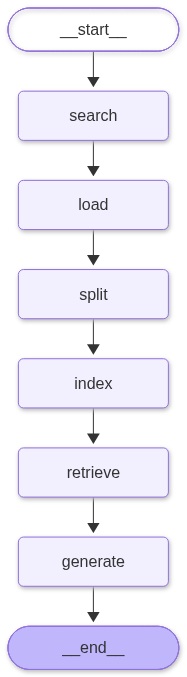

In [10]:
app

정상적으로 선언됐다는 것을 확인할 수 있습니다!!

---
# ✍🏻 생성 모델 실습

Fashion MNIST 데이터를 이용해 AE·VAE·GAN·Diffusion 모델의 핵심 원리를 확인합니다. **AE는 짧게 학습**하고, VAE·GAN·Diffusion은 각각 재매개변수화·손실함수·순확산·역확산을 중심으로 실습합니다.

## 📁 라이브러리 임포트
- AutoEncoder, VAE, GAN은 tensorflow를 사용합니다.
- Diffusion Model은 torch를 사용합니다.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

import time
from tqdm.notebook import trange
from tqdm.keras import TqdmCallback
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
import copy

## 🔍 1. AutoEncoder(오토인코더)
Fashion MNIST 의류 이미지를 압축했다가 복원하는 오토인코더를 작성해 봅시다!

### 1-1.  데이터 준비
- 입력데이터 준비. Fashion MNIST 의류 이미지를 사용하며, 정답레이블은 사용하지 않습니다.
- 모든값은 0~1사이로 정규화하고 28x28이미지를 크기 (28,28,1)의 텐서로 만듭니다.

In [12]:
## Fashion MNIST 데이터 로드
(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

# 정규화 및 reshape
x_train = x_train.astype('float32')/255.
x_test = x_test.astype('float32')/255.
x_train = x_train.***((-1, 28, 28, 1))      #reshape()를 호출해 훈련데이터를 (배치크기, 28, 28, 1)로 설정합니다.
x_test = x_test.***((-1, 28, 28, 1))


print("훈련 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
훈련 데이터: (60000, 28, 28, 1)
테스트 데이터: (10000, 28, 28, 1)


### 1-2. AutoEncoder 모델 정의

In [13]:
# Conv2D 기반 오토인코더 구조입니다.
# 인코더: Conv2D + MaxPooling2D 로 특징 추출
# 디코더: Conv2D + UpSampling2D 로 이미지 복원
input_img = tf.keras.layers.Input(shape=(28, 28, 1))

# 인코더
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
encoded = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)

# 디코더
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
decoded = tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)  # 출력 픽셀값을 [0,1]로 제한하기 위해 sigmoid 사용 (입력 데이터 정규화가 [0,1]인 경우)

autoencoder = tf.keras.Model(input_img, decoded)


In [14]:
#모델컴파일. 먼저 화소당 MSE손실을 사용하고, optimizer로 'adam'을 사용합니다.
autoencoder.compile(optimizer='***', loss=tf.keras.losses.***())

### 1-3. AutoEncoder 학습
- 이제 오토인코더를 15에폭동안 학습시켜봅시다.

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 579ms/step - loss: 0.1564 - val_loss: 0.1212
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0754 - val_loss: 0.0427
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.0403 - val_loss: 0.0348
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0337 - val_loss: 0.0326
Epoch 5/15
5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0304

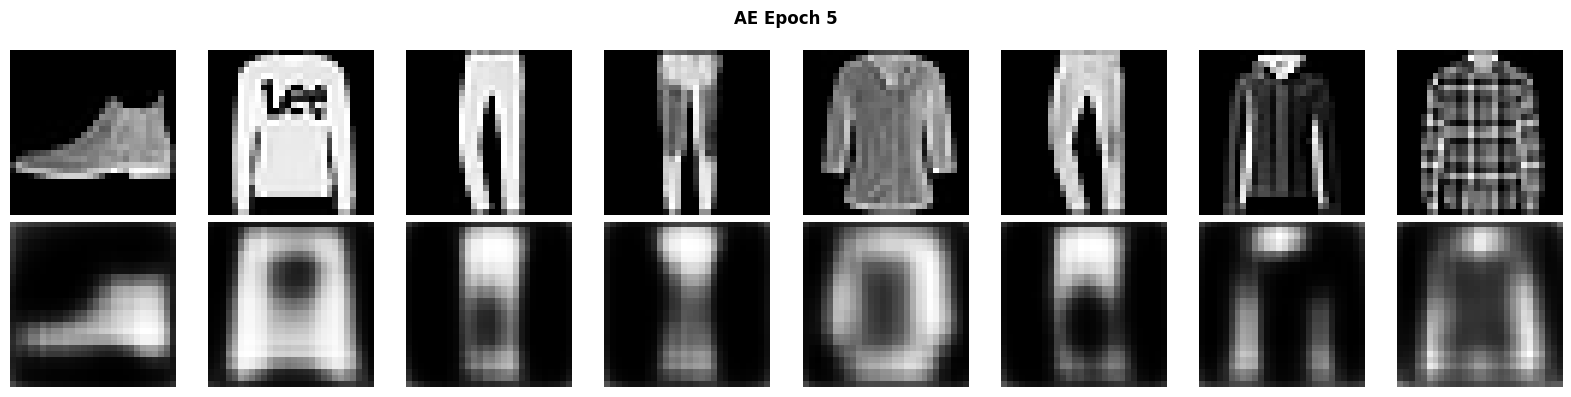

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 447ms/step - loss: 0.0294 - val_loss: 0.0281
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0263 - val_loss: 0.0253
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0238 - val_loss: 0.0233
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0219 - val_loss: 0.0214
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0205 - val_loss: 0.0202
Epoch 10/15
5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0197

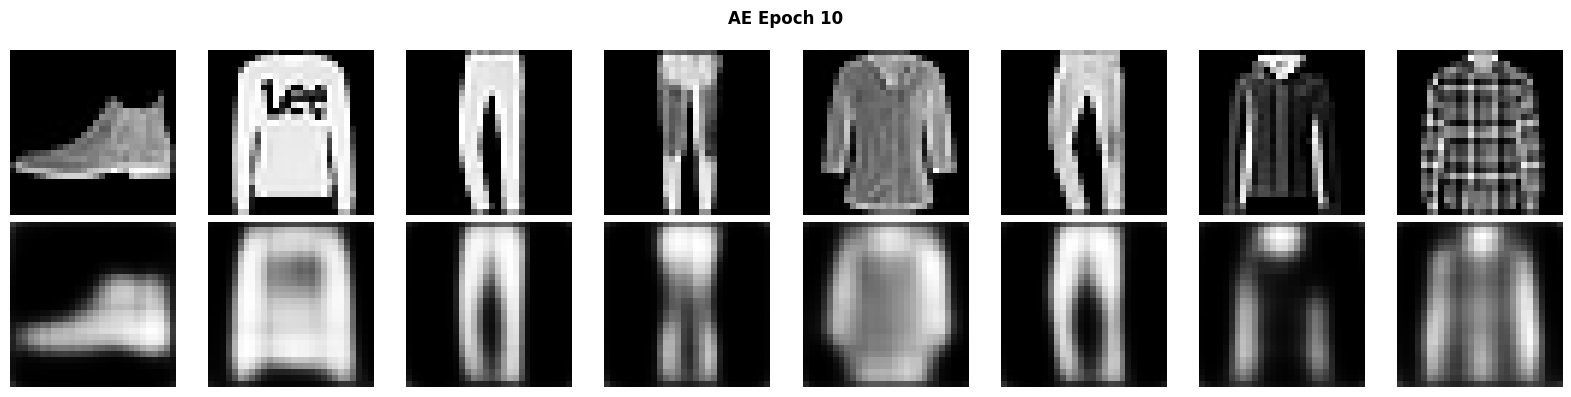

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0193 - val_loss: 0.0190
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0182 - val_loss: 0.0181
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0179 - val_loss: 0.0181
Epoch 13/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0174 - val_loss: 0.0170
Epoch 14/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.0163 - val_loss: 0.0163
Epoch 15/15
5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0161 

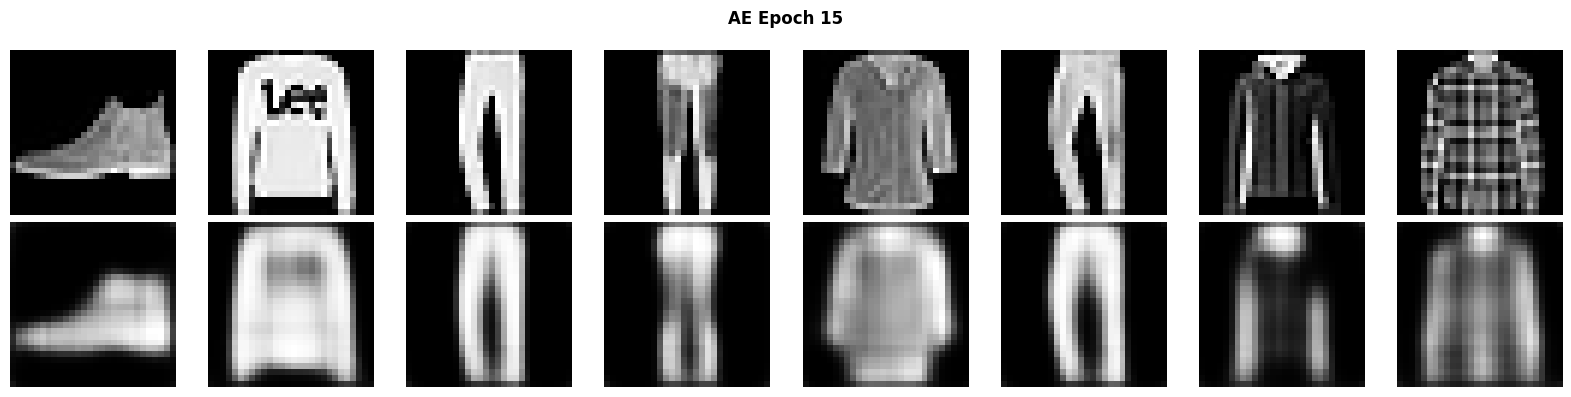

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 200ms/step - loss: 0.0158 - val_loss: 0.0162


In [15]:
# ✅ 에폭별 재구성 이미지 시각화 콜백 (윗줄: 원본, 아랫줄: 재구성)
class VisualizeCallback(tf.keras.callbacks.Callback):
    def __init__(self, x_sample, every=5):
        super().__init__()
        self.x_sample = x_sample
        self.every = every

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0:
            decoded = self.model.predict(self.x_sample, verbose=0)
            n = len(self.x_sample)
            fig, axes = plt.subplots(2, n, figsize=(n * 2, 4))
            for i in range(n):
                axes[0, i].imshow(self.x_sample[i].reshape(28, 28), cmap='gray')
                axes[0, i].axis('off')
                axes[1, i].imshow(decoded[i].reshape(28, 28), cmap='gray')
                axes[1, i].axis('off')
            plt.suptitle(f'AE Epoch {epoch+1}', fontsize=12, fontweight='bold')
            plt.tight_layout()
            plt.show()

history = autoencoder.fit(
    x_train[:2048], x_train[:2048],       # AE는 입력과 정답 모두 원본 이미지입니다.
    epochs=15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test[:256], x_test[:256]),
    verbose=1,
    callbacks=[VisualizeCallback(x_test[:8], every=5)]
)


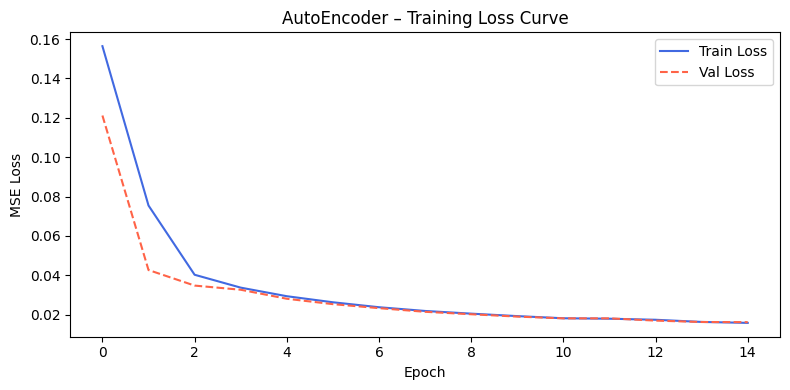

In [16]:
# ✅ AE 학습 수렴 곡선
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'],     label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss',   color='tomato', linestyle='--')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('AutoEncoder – Training Loss Curve')
plt.legend(); plt.tight_layout(); plt.show()


#### **💡 Loss 곡선이 우하향할수록 모델이 잘 수렴하고 있다는 뜻입니다.**

Train/Val Loss 차이가 크면 과적합(Overfitting)을 의심해볼 수 있습니다.

### 1-4. 재복원 결과 시각화
- 이제는 맷플롯립을 이용해 x_test에 포함된 원본이미지와 재복원된 이미지를 화면에 그려봅시다.

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


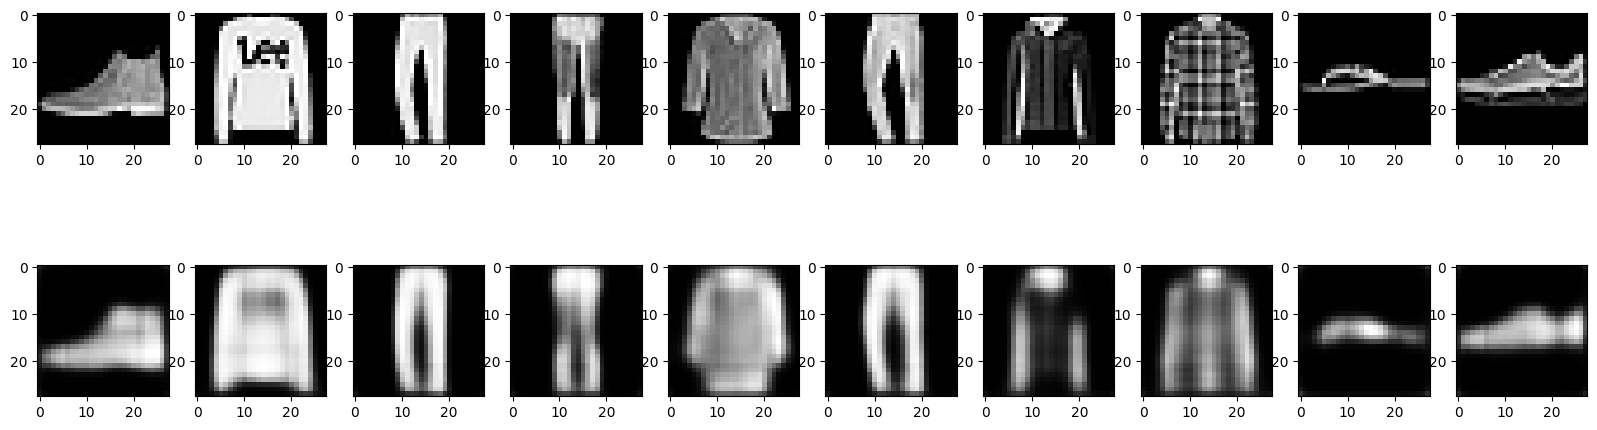

In [17]:
decoded_imgs = autoencoder.predict(***)  # 어떤데이터를 예측해야할까요?

n=10
plt.figure(figsize=(20, 6))
for i in range(n):
    ax = plt.subplot(2, n, i+1)
    plt.imshow(***[i].reshape(28,28), cmap='gray')    #원본이미지

    ax = plt.subplot(2, n, i+1+n)
    plt.imshow(***[i].reshape(28,28), cmap='gray')   # 재구성된 이미지
plt.show()

#### **💡 윗줄은 원래 의류 이미지고, 아랫줄은 재구성된 의류 이미지입니다!**

※ 이번에는 학습 횟수를 줄였으므로 재구성된 이미지가 흐릿할 수 있습니다.

## 🔍 2. VAE

- VAE로도 Fashion MNIST 이미지의 특징을 잠재 벡터로 표현해볼까요?

※ 여기서는 VAE 전체 학습 대신 인코더·샘플링·디코더의 구조를 확인합니다.

In [18]:
latent_dim = 32  # 잠재 공간 차원 (Fashion MNIST의 복잡도를 반영해 32로 설정)

In [19]:
# ----- 인코더 -----
encoder_inputs = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

VAE의 목적은 입력 $X$를 확률 분포 $P(z|X)$를 따르는 잠재 벡터 $z$로 인코딩하는 것입니다.

이 과정에서 $z$를 샘플링하게 되는데, 일반적인 무작위 샘플링은 역전파(Backpropagation)를 통해 모델의 가중치를 업데이트할 수 없다는 문제가 있습니다.

재매개변수화 트릭은 이 문제를 해결하여 $z$를 생성하는 과정에 '무작위성(Randomness)'을 유지하면서도 '미분 가능성(Differentiability)'을 확보합니다.

In [20]:
# 재매개변수화 트릭


def sampling(args):
    ***, *** = args      #z의 평균과 로그분산을 샘플링합니다!
    eps = tf.***.normal(shape=(tf.shape(z_mean)[0], latent_dim))   # 무작위성을 줍시다! 무작위는영어로?
    return z_mean + tf.exp(0.5 * z_log_var) * eps   # return값이 잠재벡터 z의 공식이 됩니다.

z = layers.Lambda(sampling, name="z")([z_mean, z_log_var])
encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 14, 14,    │        320 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    401,536 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 428,608 (1.64 MB)

 Trainable params: 428,608 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# ----- 디코더 -----
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 128, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 128))(x)
x = layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)
decoder = Model(latent_inputs, decoder_outputs, name="decoder")  # 디코더의 입력과 출력 변수를 넣어주세요!
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6272)           │       206,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 428,929 (1.64 MB)

 Trainable params: 428,929 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

※ 여기서는 VAE를 학습시키지 않고 인코더·디코더 구조와 샘플링 결과만 확인합니다.

In [22]:
z_mu, z_lv, z_sample = encoder(x_test[:1])
print("잠재 벡터 평균 shape:", z_mu.shape)
print("샘플링 잠재 벡터 shape:", z_sample.shape)


잠재 벡터 평균 shape: (1, 32)
샘플링 잠재 벡터 shape: (1, 32)


**💡 VAE의 잠재 벡터**
- `잠재 벡터 평균 shape: (1, 32)`와 `샘플링 잠재 벡터 shape: (1, 32)`는 이미지 1장이 32차원의 잠재 벡터로 표현되었음을 의미합니다.

**💡 VAE 손실은 두 가지로 구성됩니다.**
- **Recon Loss**: 입력 이미지를 얼마나 정확하게 복원했는지 측정 (낮을수록 좋음)
- **KL Loss**: 잠재 공간 분포가 표준 정규분포에 얼마나 가까운지 측정 (낮을수록 좋음)

※ 이번 실습에서는 VAE 학습을 생략했으므로 위의 Recon Loss와 KL Loss 값은 출력되지 않습니다.

## 🔍 3. GAN

이번엔 생성자(Generator)와 판별자(Discriminator)를 번갈아 학습시켜 Fashion MNIST 의류 이미지를 새로 생성해봅시다.

※ 여기서는 생성자와 판별자의 손실함수를 확인하기 위해 **GAN을 한 번만 업데이트**합니다.

In [23]:
# Fashion MNIST 데이터 로드
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# [0, 1] → [-1, 1] 스케일링 (GAN에서는 tanh 출력 맞추기 위함)
x_train = (x_train.astype(np.float32) - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BUFFER_SIZE = 60000
BATCH_SIZE = 32

# tf.data로 배치 구성
train_dataset = tf.data.Dataset.from_tensor_slices(x_train[:1024]).shuffle(1024).batch(BATCH_SIZE)


### 3-2. 생성자(Generator) 모델 정의

In [24]:
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*256, use_bias=False, input_shape=(100,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
    ])
    return model

generator = make_generator_model()  #위에서 정의한 생성자 함수!
generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

### 3-3. 판별자(Discriminator) 모델 정의

In [25]:
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same',
                      input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

discriminator = make_discriminator_model()  #위에서 정의한 판별자 함수!
discriminator.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

### 3-4. 손실함수 및 옵티마이저 설정

In [26]:
# ✅ 손실 함수 정의
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    # 생성자는 판별자를 '진짜'라고 속여야 하므로 레이블 = 1
    return ***_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    # 판별자는 진짜=1, 가짜=0 으로 분류해야 함
    real_loss = cross_entropy(tf.***(real_output),  real_output)
    fake_loss = cross_entropy(tf.***(fake_output), fake_output)
    return real_loss + fake_loss        # 총 손실은 두 손실의 합입니다!

# GAN 학습 안정화를 위해 beta_1=0.5 사용 (일반적인 GAN 권장 설정)
generator_optimizer     = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)


### 3-5. 학습 루프 정의

In [27]:
noise_dim = 100
num_examples_to_generate = 16

# 고정 시드(매번 같은 예시 생성)
seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss



아래 셀에서 GAN을 **1회 학습 업데이트**하고 Generator Loss와 Discriminator Loss를 출력해 봅시다.

In [28]:
gan_batch = next(iter(train_dataset))
gen_loss, disc_loss = train_step(gan_batch)
print(f"Generator Loss: {float(gen_loss):.4f}")
print(f"Discriminator Loss: {float(disc_loss):.4f}")


Generator Loss: 0.6931
Discriminator Loss: 1.3849


**💡 GAN 손실 해석 포인트**
- **Disc Loss → 0**: 판별자가 실제 이미지와 생성 이미지를 잘 구분하고 있을 수 있습니다.
- **Gen Loss → 0**: 생성자가 판별자를 잘 속이고 있을 수 있습니다.

※ 두 손실값이 비슷하다는 이유만으로 학습 상태나 이미지 품질이 좋다고 판단할 수는 없습니다. 이번에는 학습 업데이트 1회 결과만 확인합니다.

## 🔍 4. Diffusion Model (확산 모형)

이번에는 **순확산(Forward Diffusion)** 과정에서 원본 이미지에 노이즈가 더해지는 모습을 확인합니다.

### 4-1. 데이터 준비

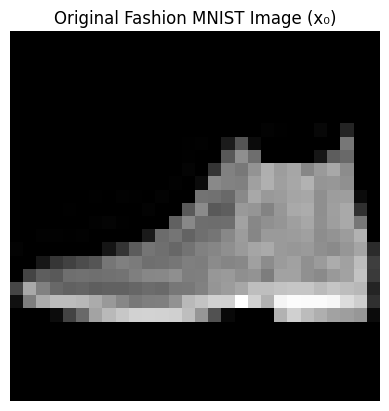

In [29]:
# 앞서 AE에서 준비한 Fashion MNIST 이미지를 사용합니다.
device = "cuda" if torch.cuda.is_available() else "cpu"
x0_sample = torch.tensor(x_test[0]).permute(2, 0, 1).float()

plt.imshow(x0_sample.squeeze(), cmap='gray')
plt.axis('off')
plt.title("Original Fashion MNIST Image (x₀)")
plt.show()


### 4-2. 순확산 (Forward Diffusion)

In [30]:
T = 300  # total diffusion steps
beta = torch.linspace(1e-4, 0.02, T).to(device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [31]:
# ✅ 배치 단위로 노이즈 추가
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    sqrt_ab = torch.sqrt(alpha_bar[t]).view(-1, 1, 1, 1)    # 원본데이터(x0)에 곱해지는 가중치
    sqrt_1_ab = torch.sqrt(1 - alpha_bar[t]).view(-1, 1, 1, 1)    # 노이즈(noise)에 곱해지는 가중치
    return sqrt_ab * *** + sqrt_1_ab * ***   # 가중치에 원본데이터와 노이즈를 곱해줍시다!


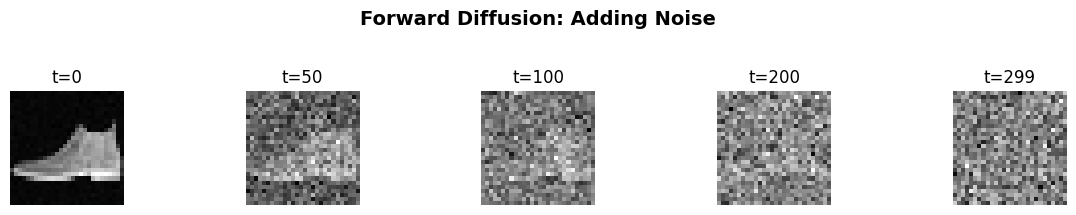

In [32]:
# ✅ 순확산 시각화 (샘플 한 장)
x0 = x0_sample.unsqueeze(0).to(device)  # [1,1,28,28]
plt.figure(figsize=(12, 2))
for i, t in enumerate([0, 50, 100, 200, 299]):
    xt = add_noise(x0, torch.tensor([t], device=device))
    plt.subplot(1, 5, i + 1)
    plt.imshow(xt.squeeze().cpu(), cmap='gray')
    plt.axis('off')
    plt.title(f"t={t}")
plt.suptitle("Forward Diffusion: Adding Noise", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**💡 노이즈가 잘 추가된 것을 확인할 수 있습니다!**

`t`가 커질수록 이미지에 노이즈가 더 많이 섞여 원본 형태를 구분하기 어려워집니다. 이어서 노이즈를 제거하는 역확산도 실행해봅시다!

### 4-3. 역확산 (Reverse Diffusion)

In [33]:
# 역확산 학습용 데이터 (0~1 범위, [배치, 1, 28, 28])
(x_diff, _), _ = tf.keras.datasets.fashion_mnist.load_data()
x_diff = torch.tensor(x_diff, dtype=torch.float32).unsqueeze(1) / 255.
train_loader = torch.utils.data.DataLoader(x_diff, batch_size=64, shuffle=True)

# ✅ 타임스텝 t를 함께 입력받는 CNN 기반 denoiser
# 노이즈 제거는 타임스텝(t)에 따라 달라야 하므로 t 정보를 모델에 주입합니다.
class SimpleDenoiser(nn.Module):
    def __init__(self, T=300):
        super().__init__()
        self.time_emb  = nn.Embedding(T, 64)
        self.time_proj = nn.Linear(64, 128)

        self.enc1 = nn.Conv2d(1,   64,  3, padding=1)
        self.enc2 = nn.Conv2d(64,  128, 3, stride=2, padding=1)
        self.mid  = nn.Conv2d(128, 128, 3, padding=1)
        self.dec1 = nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1)
        self.out  = nn.Conv2d(64, 1, 3, padding=1)

    def forward(self, x, t):
        t_emb = F.relu(self.time_proj(self.time_emb(t)))
        t_emb = t_emb.view(-1, 128, 1, 1)

        h1 = F.relu(self.enc1(x))    # [B, 64, 28, 28]
        h2 = F.relu(self.enc2(h1))   # [B, 128, 14, 14]
        h2 = h2 + t_emb              # 타임스텝 정보 주입
        h2 = F.relu(self.mid(h2))    # [B, 128, 14, 14]
        h3 = F.relu(self.dec1(h2))   # [B, 64, 28, 28]
        return torch.sigmoid(self.out(h3 + h1))  # 원본 이미지(0~1)를 예측

model = SimpleDenoiser(T=T).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
loss_fn = nn.MSELoss()

In [34]:
# 역확산: 노이즈에서 시작해 모델의 예측 쪽으로 조금씩 이동
@torch.no_grad()
def reverse_diffusion(model, steps=10):
    x = torch.randn((1, 1, 28, 28), device=device)  # 완전 노이즈에서 시작
    images = [x.cpu()]
    for i in range(steps):
        t_val = max(0, T - 1 - i * (T // steps))
        t_tensor = torch.tensor([t_val], device=device)
        denoised = model(x, t_tensor)
        x = x - 0.3 * (x - denoised)       # 단순화한 denoising step
        images.append(x.cpu())
    return images

In [35]:
# 학습
for epoch in range(10):
    epoch_losses = []
    for x_batch in train_loader:
        x_batch = x_batch.to(device)
        t = torch.randint(0, T, (x_batch.size(0),), device=device)
        xt = add_noise(x_batch, t)
        pred = model(xt, t)
        loss = loss_fn(pred, x_batch)

        optimizer.zero_grad()
        loss.***()       #역전파
        optimizer.step()
        epoch_losses.append(loss.item())

    print(f'Epoch {epoch + 1}, loss = {sum(epoch_losses) / len(epoch_losses):.4f}')

Epoch 1, loss = 0.0519
Epoch 2, loss = 0.0420
Epoch 3, loss = 0.0403
Epoch 4, loss = 0.0392
Epoch 5, loss = 0.0387
Epoch 6, loss = 0.0384
Epoch 7, loss = 0.0380
Epoch 8, loss = 0.0379
Epoch 9, loss = 0.0376
Epoch 10, loss = 0.0374


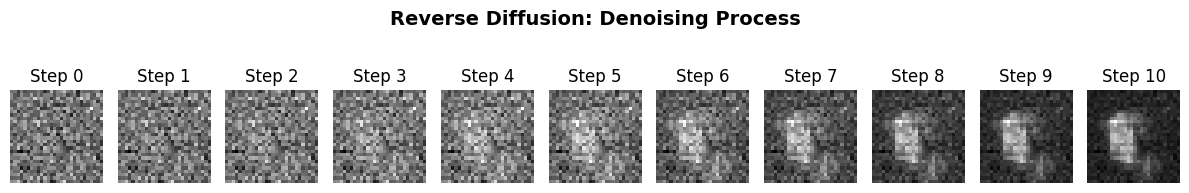

In [36]:
# 시각화
images = ***(model, steps=10)     #위에서 정의한 역확산 함수!

plt.figure(figsize=(12, 2))
for i, img in enumerate(images):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(img.squeeze(), cmap='gray')
    plt.axis('off')
    plt.title(f"Step {i}")
plt.suptitle("Reverse Diffusion: Denoising Process", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**💡 노이즈가 점점 걷히며 형태가 나타나는 과정을 확인해 봅시다.**

※ 이번 역확산은 계산을 단순화했기 때문에 선명한 의류 이미지가 생성되지 않을 수 있습니다.

## 수고하셨습니다~! 🥳